In [2]:
# Libreria para cargar nuestro drive
from google.colab import drive
# Cargamos nuestro drive en nuestro notebook
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import os
os.chdir('/content/drive/MyDrive/Proyectos/Proyecto_Plantas_Enfermedades')

In [4]:
import tensorflow as tf
import numpy as np
import random

seed = 42

tf.random.set_seed(seed)
np.random.seed(seed)
random.seed(seed)

In [5]:
import pandas as pd

ndf = pd.read_csv("/content/drive/MyDrive/Proyectos/Proyecto_Plantas_Enfermedades/ndf_final.csv")

In [6]:
import os
import shutil

BASE_DRIVE = "/content/drive/MyDrive/Proyectos/Proyecto_Plantas_Enfermedades"

src_plantvillage = os.path.join(BASE_DRIVE, "PlantVillage")
src_aug = os.path.join(BASE_DRIVE, "aug")

dst_plantvillage = "/content/PlantVillage"
dst_aug = "/content/aug"

# 🔥 Copiar PlantVillage
if not os.path.exists(dst_plantvillage):
    shutil.copytree(src_plantvillage, dst_plantvillage)
    print("PlantVillage copiado a /content")
else:
    print("PlantVillage ya existe en /content")

# 🔥 Copiar aug
if not os.path.exists(dst_aug):
    shutil.copytree(src_aug, dst_aug)
    print("Aug copiado a /content")
else:
    print("Aug ya existe en /content")

PlantVillage copiado a /content
Aug copiado a /content


In [7]:
import pandas as pd

ndf = pd.read_csv(BASE_DRIVE + "/ndf_final.csv")

# 🔥 convertir rutas de Drive → /content (CLAVE para velocidad)
ndf['filepaths'] = ndf['filepaths'].str.replace(
    BASE_DRIVE,
    "/content"
)

print("Dataset cargado en /content:")
print(ndf.shape)
print(ndf['labels'].value_counts())

Dataset cargado en /content:
(7500, 2)
labels
Pepper__bell___Bacterial_spot                  500
Pepper__bell___healthy                         500
Potato___Early_blight                          500
Potato___Late_blight                           500
Potato___healthy                               500
Tomato_Bacterial_spot                          500
Tomato_Early_blight                            500
Tomato_Late_blight                             500
Tomato_Leaf_Mold                               500
Tomato_Septoria_leaf_spot                      500
Tomato_Spider_mites_Two_spotted_spider_mite    500
Tomato__Target_Spot                            500
Tomato__Tomato_YellowLeaf__Curl_Virus          500
Tomato__Tomato_mosaic_virus                    500
Tomato_healthy                                 500
Name: count, dtype: int64


In [8]:
from sklearn.model_selection import train_test_split

# 80% train, 20% temporal
train_df, temp_df = train_test_split(
    ndf,
    test_size=0.2,
    stratify=ndf['labels'],
    random_state=42
)

# 10% val, 10% test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    stratify=temp_df['labels'],
    random_state=42
)

print("TRAIN:\n", train_df['labels'].value_counts())
print("\nVAL:\n", val_df['labels'].value_counts())
print("\nTEST:\n", test_df['labels'].value_counts())

TRAIN:
 labels
Tomato__Tomato_YellowLeaf__Curl_Virus          400
Tomato_Leaf_Mold                               400
Tomato__Target_Spot                            400
Tomato_healthy                                 400
Potato___Late_blight                           400
Potato___Early_blight                          400
Tomato_Bacterial_spot                          400
Pepper__bell___Bacterial_spot                  400
Tomato_Late_blight                             400
Tomato_Septoria_leaf_spot                      400
Potato___healthy                               400
Tomato__Tomato_mosaic_virus                    400
Tomato_Spider_mites_Two_spotted_spider_mite    400
Tomato_Early_blight                            400
Pepper__bell___healthy                         400
Name: count, dtype: int64

VAL:
 labels
Tomato__Tomato_mosaic_virus                    50
Tomato_Bacterial_spot                          50
Tomato__Tomato_YellowLeaf__Curl_Virus          50
Tomato_Spider_mites_Two_spotte

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

'''
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=10,
    zoom_range=0.1,
    width_shift_range=0.05,
    height_shift_range=0.05,
    horizontal_flip=True
)
'''

train_datagen = ImageDataGenerator(rescale=1./255)
val_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_dataframe(
    train_df,
    x_col='filepaths',
    y_col='labels',
    target_size=(224,224),
    class_mode='categorical',
    batch_size=32,
    shuffle=True,
    seed=42
)

val_generator = val_datagen.flow_from_dataframe(
    val_df,
    x_col='filepaths',
    y_col='labels',
    target_size=(224,224),
    class_mode='categorical',
    batch_size=32,
    shuffle=False,
    seed=42
)

test_generator = val_datagen.flow_from_dataframe(
    test_df,
    x_col='filepaths',
    y_col='labels',
    target_size=(224,224),
    class_mode='categorical',
    batch_size=32,
    shuffle=False
)

Found 6000 validated image filenames belonging to 15 classes.
Found 750 validated image filenames belonging to 15 classes.
Found 750 validated image filenames belonging to 15 classes.


## 🔬 Experimento 1: CNN Propuesta

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, BatchNormalization,
    GlobalAveragePooling2D, Dense, Dropout, Input
)

num_classes = len(train_generator.class_indices)

model = Sequential()

# Entrada
model.add(Input(shape=(224,224,3)))

# Bloque 1
model.add(Conv2D(32, (3,3), padding='same', activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(2,2))

# Bloque 2
model.add(Conv2D(64, (3,3), padding='same', activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(2,2))

# Bloque 3
model.add(Conv2D(128, (3,3), padding='same', activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(2,2))

# Bloque 4 (sin sobrecargar)
model.add(Conv2D(256, (3,3), padding='same', activation='relu'))
model.add(MaxPooling2D(2,2))

model.add(GlobalAveragePooling2D())

# Clasificación (más ligera)
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.3))   # menos agresivo

model.add(Dense(num_classes, activation='softmax'))

model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_12 (Conv2D)              │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_11          │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_12          │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_8      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 15)             │         1,935 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 424,143 (1.62 MB)

 Trainable params: 423,695 (1.62 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=1e-4),  # 🔥 clave
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

In [ ]:
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=20,
    callbacks=[early_stop]
)

Epoch 1/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 30s 125ms/step - accuracy: 0.4305 - loss: 1.8049 - val_accuracy: 0.0667 - val_loss: 3.5786
Epoch 2/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 15s 81ms/step - accuracy: 0.6293 - loss: 1.1698 - val_accuracy: 0.0707 - val_loss: 4.2735
Epoch 3/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 15s 81ms/step - accuracy: 0.7067 - loss: 0.9455 - val_accuracy: 0.3880 - val_loss: 1.7593
Epoch 4/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 15s 79ms/step - accuracy: 0.7377 - loss: 0.8093 - val_accuracy: 0.7933 - val_loss: 0.6751
Epoch 5/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 15s 80ms/step - accuracy: 0.7740 - loss: 0.7145 - val_accuracy: 0.8440 - val_loss: 0.5350
Epoch 6/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 15s 80ms/step - accuracy: 0.7947 - loss: 0.6564 - val_accuracy: 0.8307 - val_loss: 0.5031
Epoch 7/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 16s 84ms/step - accuracy: 0.8133 - loss: 0.5911 - val_accuracy: 0.8600 - val_loss: 0.4342
Epoch 8/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 15s 81ms/step - accuracy: 0.8308 - loss: 0.5258 -

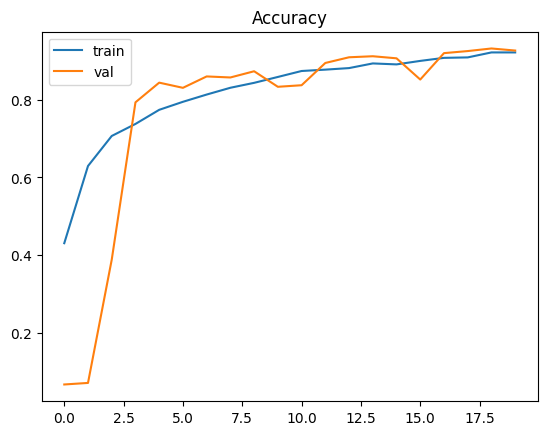

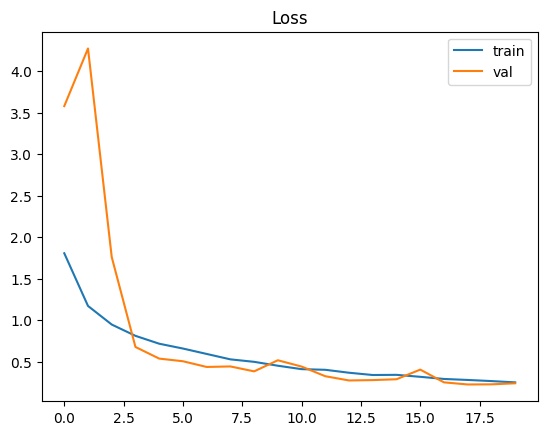

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.legend()
plt.title("Accuracy")
plt.show()

plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.legend()
plt.title("Loss")
plt.show()

In [ ]:
loss, acc = model.evaluate(test_generator)

print(f"Test Loss: {loss}")
print(f"Test Accuracy: {acc}")

24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - accuracy: 0.9320 - loss: 0.2059
Test Loss: 0.20588700473308563
Test Accuracy: 0.9319999814033508


In [ ]:
import numpy as np

predictions = model.predict(test_generator)
y_pred = np.argmax(predictions, axis=1)

24/24 ━━━━━━━━━━━━━━━━━━━━ 7s 187ms/step


In [ ]:
y_true = test_generator.classes
class_names = list(test_generator.class_indices.keys())

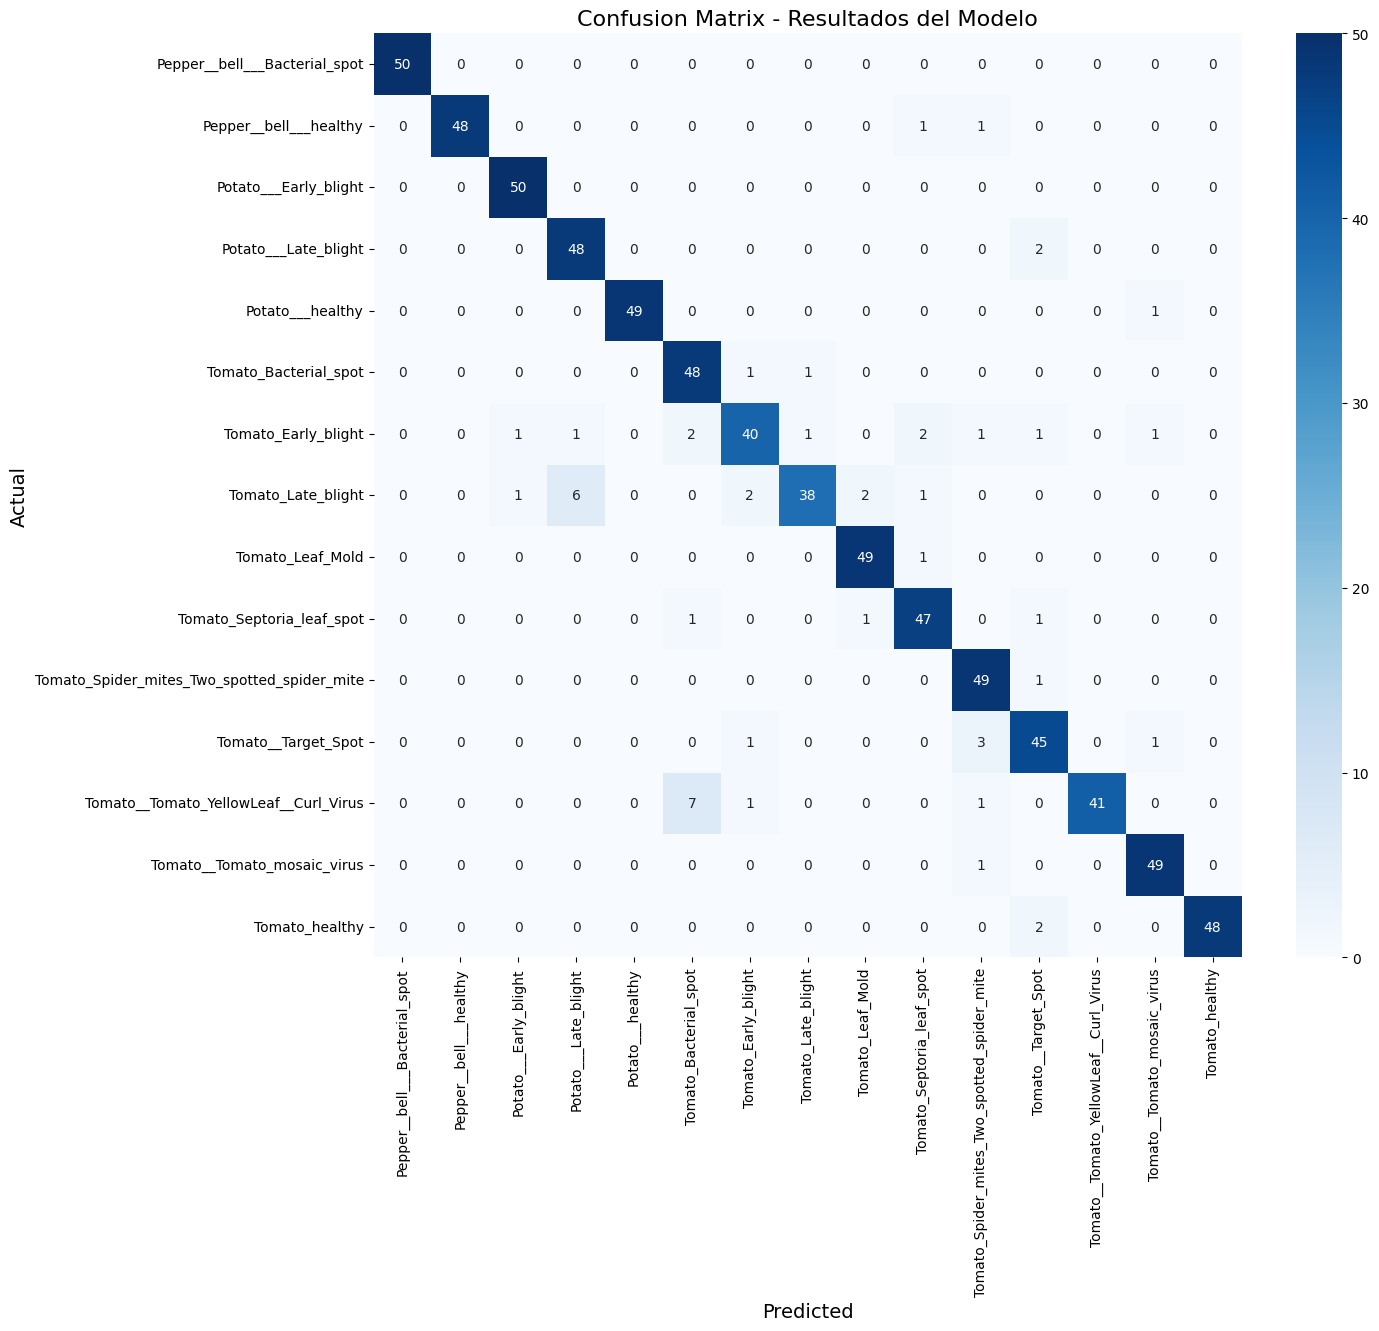

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Generamos la matriz
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(14, 12))
sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names,
            annot_kws={"size": 10})

plt.xlabel("Predicted", fontsize=14)
plt.ylabel("Actual", fontsize=14)
plt.title("Confusion Matrix - Resultados del Modelo", fontsize=16)
plt.xticks(rotation=90) # Rota las etiquetas para que se lean bien
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_true, y_pred, target_names=class_names))

                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       1.00      1.00      1.00        50
                     Pepper__bell___healthy       1.00      0.96      0.98        50
                      Potato___Early_blight       0.96      1.00      0.98        50
                       Potato___Late_blight       0.87      0.96      0.91        50
                           Potato___healthy       1.00      0.98      0.99        50
                      Tomato_Bacterial_spot       0.83      0.96      0.89        50
                        Tomato_Early_blight       0.89      0.80      0.84        50
                         Tomato_Late_blight       0.95      0.76      0.84        50
                           Tomato_Leaf_Mold       0.94      0.98      0.96        50
                  Tomato_Septoria_leaf_spot       0.90      0.94      0.92        50
Tomato_Spider_mites_Two_spotted_spider_mite       0.88      0.98

## 🔬 Experimento 2: Modelo EfficientNet


In [9]:
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=10,
    zoom_range=0.1,
    width_shift_range=0.05,
    height_shift_range=0.05,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

In [10]:
train_generator = train_datagen.flow_from_dataframe(
    train_df,
    x_col='filepaths',
    y_col='labels',
    target_size=(224,224),
    class_mode='categorical',
    batch_size=32,
    shuffle=True,
    seed=42
)

val_generator = val_datagen.flow_from_dataframe(
    val_df,
    x_col='filepaths',
    y_col='labels',
    target_size=(224,224),
    class_mode='categorical',
    batch_size=32,
    shuffle=False,
    seed=42
)

test_generator = val_datagen.flow_from_dataframe(
    test_df,
    x_col='filepaths',
    y_col='labels',
    target_size=(224,224),
    class_mode='categorical',
    batch_size=32,
    shuffle=False
)

Found 6000 validated image filenames belonging to 15 classes.
Found 750 validated image filenames belonging to 15 classes.
Found 750 validated image filenames belonging to 15 classes.


In [11]:
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, BatchNormalization
from tensorflow.keras.models import Model

# Modelo base
base_model = EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)

# Congelar capas
for layer in base_model.layers:
    layer.trainable = False

# Head
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = BatchNormalization()(x)

x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)

output = Dense(len(train_generator.class_indices), activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=output)

model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        512 │ block1a_se_excit

 Total params: 4,386,482 (16.73 MB)

 Trainable params: 334,351 (1.28 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

In [12]:
from tensorflow.keras.optimizers import Adam
model.compile(
    optimizer = Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [13]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

In [ ]:
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=20,
    callbacks=[early_stop]
)

Epoch 1/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 141s 580ms/step - accuracy: 0.6922 - loss: 1.0091 - val_accuracy: 0.8960 - val_loss: 0.4405
Epoch 2/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 72s 382ms/step - accuracy: 0.8468 - loss: 0.4745 - val_accuracy: 0.9160 - val_loss: 0.2336
Epoch 3/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 72s 385ms/step - accuracy: 0.8775 - loss: 0.3704 - val_accuracy: 0.9253 - val_loss: 0.1903
Epoch 4/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 72s 380ms/step - accuracy: 0.8908 - loss: 0.3406 - val_accuracy: 0.9387 - val_loss: 0.1702
Epoch 5/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 72s 383ms/step - accuracy: 0.8938 - loss: 0.3239 - val_accuracy: 0.9267 - val_loss: 0.1918
Epoch 6/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 72s 383ms/step - accuracy: 0.9053 - loss: 0.2722 - val_accuracy: 0.9440 - val_loss: 0.1695
Epoch 7/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 74s 391ms/step - accuracy: 0.9197 - loss: 0.2366 - val_accuracy: 0.9467 - val_loss: 0.1482
Epoch 8/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 74s 392ms/step - accuracy: 0.9190 - loss: 

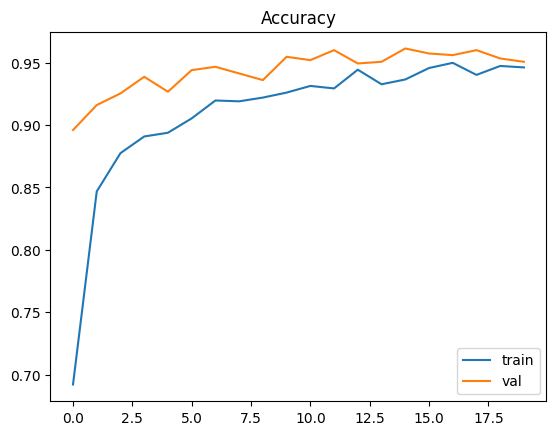

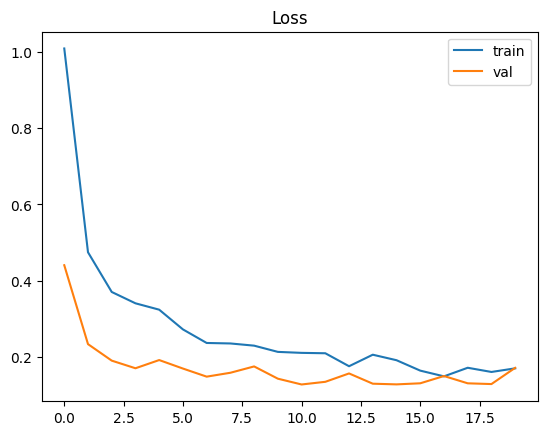

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.legend()
plt.title("Accuracy")
plt.show()

plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.legend()
plt.title("Loss")
plt.show()

In [ ]:
test_loss, test_acc = model.evaluate(test_generator)

print(f"Test accuracy: {test_acc}")
print(f"Test loss: {test_loss}")

24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - accuracy: 0.9547 - loss: 0.1672
Test accuracy: 0.9546666741371155
Test loss: 0.16724878549575806
